<h1> Modul 05 - Unsupervised Learning (Clustering) Part 1 </h1>

**Nama:** Erhan Kurniawan  
**NIM:** 124140217  
**Kelas:** IF25-31020 Pembelajaran Mesin  

Modul ini mengeksplorasi **clustering** pada dataset **Mall Customers** (200 pelanggan, 5 kolom) menggunakan dua pendekatan:

1. **K-Means** dengan evaluasi **Silhouette Score**.
2. **Agglomerative Clustering** dengan evaluasi **Davies-Bouldin Index (DBI)**.

Sebelum clustering, data melewati tahap **Data Loading and Preparation**: konversi `Gender` ke numerik, pemilihan fitur, dan normalisasi Min-Max. PCA 3 komponen dipakai hanya untuk visualisasi 3D, bukan untuk proses clustering.

> **Catatan adaptasi:** modul asli memuat data langsung dari Kaggle melalui Google Colab. Notebook ini memakai file lokal `./data/Mall_Customers.csv` agar dapat dijalankan mandiri.

Dataset: [Customer Segmentation Tutorial](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)


# Data Loading and Preparation

Tahap ini memastikan data siap dipakai untuk clustering:

- memuat library yang dibutuhkan,
- membaca dataset,
- memeriksa tipe data,
- mengonversi kolom kategorikal (`Gender`) menjadi numerik,
- memilih fitur yang relevan,
- menormalkan skala fitur.

Tujuannya agar setiap fitur memiliki rentang yang sebanding sehingga tidak ada fitur yang mendominasi perhitungan jarak.


## Import Library

- `pandas`: membaca CSV dan manipulasi tabel.
- `matplotlib.pyplot`: visualisasi grafik dan scatter 3D.
- `seaborn`: disiapkan untuk visualisasi statistik (belum dipakai langsung pada blok ini).
- `os`: utilitas path (disiapkan, belum dipakai langsung).
- `sklearn.preprocessing.MinMaxScaler`: normalisasi ke rentang [0, 1].
- `sklearn.decomposition.PCA`: reduksi dimensi untuk visualisasi 3D.
- `sklearn.metrics.silhouette_score`: evaluasi kualitas klaster K-Means.
- `sklearn.metrics.davies_bouldin_score`: evaluasi kualitas klaster Agglomerative.
- `sklearn.cluster.KMeans` dan `AgglomerativeClustering`: dua algoritma clustering yang dibandingkan.


In [1]:
# Memuat library yang dibutuhkan dalam pemrosesan data dan pembuatan
# model dengan menggunakan K-Means dan Agglomerative clustering.
import matplotlib.pyplot as plt
import pandas as pd
import os
import seaborn as sns
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans, AgglomerativeClustering

## Memuat Dataset

`pd.read_csv()` membaca `./data/Mall_Customers.csv` dengan baris pertama sebagai header dan pemisah koma.

Dataset berisi **200 baris x 5 kolom**:

- `CustomerID`: identitas pelanggan (tidak dipakai untuk clustering),
- `Gender`: jenis kelamin,
- `Age`: usia,
- `Annual Income (k$)`: pendapatan tahunan dalam ribu dolar,
- `Spending Score (1-100)`: skor belanja pelanggan.


In [2]:
# Load data ketika file .csv telah tersimpan pada folder data proyek
path_file = "./data/Mall_Customers.csv"
dataset = pd.read_csv(path_file, header=0, sep=',')
dataset

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


## Inspeksi Tipe Data

`dataset.dtypes` memastikan tipe data setiap kolom. Hasilnya `Gender` masih bertipe `str` (teks), sedangkan empat kolom lainnya sudah numerik (`int64`). Kolom teks harus dikonversi sebelum masuk ke algoritma berbasis jarak.


In [3]:
# Mengetahui data type setiap kolom yang berhasil termuat
dataset.dtypes

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

## Konversi Gender ke Numerik

`map({'Male': 0, 'Female': 1})` mengubah kategori menjadi nilai biner:

- `Male` -> 0
- `Female` -> 1

Pengecekan `unique()` dan `dtype` memastikan konversi berhasil: nilai unik menjadi `[0 1]` dengan tipe `int64`.

> Modul asli memakai `replace` mengikuti urutan `unique()` (Female=0, Male=1). Hasil akhirnya sama-sama biner; urutan label tidak mengubah struktur clustering selama pemetaan konsisten.


In [4]:
dataset['Gender'] = dataset['Gender'].map({'Male': 0, 'Female': 1})
print(f"Nilai unik Gender: {dataset['Gender'].unique()}")  # Harus [0 1]
print(f"Tipe data Gender: {dataset['Gender'].dtype}")


Nilai unik Gender: [0 1]
Tipe data Gender: int64


## Pemisahan Fitur

`X = dataset.iloc[:, 1:5]` mengambil kolom indeks 1 sampai 4, yaitu `Gender`, `Age`, `Annual Income (k$)`, dan `Spending Score (1-100)`.

`CustomerID` sengaja dikeluarkan karena hanya identitas unik, bukan karakteristik pelanggan. Hasilnya **X berukuran (200, 4)**.


In [5]:
# Pemisahan fitur setelah Gender dikonversi ke numerik
X = dataset.iloc[:, 1:5]
print(f"Data X = {X.shape}")
X.head()


Data X = (200, 4)


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


## Verifikasi Hasil Konversi

Blok ini memverifikasi ulang bahwa `Gender` sudah numerik. Konversi hanya dilakukan sekali di blok sebelumnya, sehingga tidak terjadi mapping ganda. Blok ini bersifat *sanity check*, bukan langkah pemrosesan baru.


In [6]:
# Verifikasi hasil konversi (tidak perlu mapping ulang)
print(f"Nilai unik Gender sekarang: {dataset['Gender'].unique()}")
print(f"Tipe data Gender: {dataset['Gender'].dtype}")

dataset.head()


Nilai unik Gender sekarang: [0 1]
Tipe data Gender: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


## Normalisasi Min-Max

`MinMaxScaler` memetakan setiap fitur ke rentang [0, 1]:

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

Alasan normalisasi:

- K-Means dan Agglomerative memakai jarak Euclidean, sehingga fitur berskala besar (misalnya `Annual Income` 15-137) akan mendominasi fitur berskala kecil (misalnya `Gender` 0-1).
- Setelah normalisasi, semua fitur berada pada skala setara.
- Hasilnya diubah kembali menjadi `DataFrame` agar mudah diinspeksi.


In [7]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X)
X = pd.DataFrame(X)
print(f"Contoh data X setelah normalisasi \n{X.head()}")


Contoh data X setelah normalisasi 
     0         1         2         3
0  0.0  0.019231  0.000000  0.387755
1  0.0  0.057692  0.000000  0.816327
2  1.0  0.038462  0.008197  0.051020
3  1.0  0.096154  0.008197  0.775510
4  1.0  0.250000  0.016393  0.397959


## PCA 3 Komponen

PCA mereduksi 4 fitur menjadi **3 principal component**. Secara matematis, PCA mencari arah yang memaksimalkan varians:

$$
\max_{w} \; w^T \Sigma w \quad \text{dengan} \quad \|w\| = 1
$$

Solusi $w$ adalah eigenvector dari matriks kovarians $\Sigma$, dan eigenvalue-nya menyatakan besarnya varians pada arah tersebut.

Catatan penting: `data_pca` **hanya dipakai untuk visualisasi 3D**. Proses clustering tetap dijalankan pada `X` (4 fitur ternormalisasi) agar tidak ada informasi yang hilang.


In [8]:
# Menerapkan PCA dengan principal component sebanyak 3 untuk kebutuhan visualisasi
pca = PCA(n_components = 3)
data_pca = pca.fit_transform(X)
data_pca = pd.DataFrame(data_pca, columns=['PC1','PC2','PC3'])
data_pca.head()

,PC1,PC2,PC3
0,-0.532955,-0.227841,-0.321860
1,-0.513939,-0.493080,0.016202
2,0.446266,0.087079,-0.555761
3,0.478796,-0.366617,0.010714
4,0.451984,0.003006,-0.159208


## Analisis PCA

- Output menampilkan koordinat PC1, PC2, dan PC3 untuk setiap pelanggan.
- Tiga komponen dipilih karena 3D adalah dimensi visualisasi tertinggi yang masih mudah dibaca.
- PCA di sini berperan sebagai *projection for visualization*: label klaster nanti dipetakan ke ruang PC agar sebaran antar klaster terlihat.


# Clustering dengan K-Means dan Silhouette Score

**K-Means** mempartisi data menjadi $k$ klaster dengan meminimalkan *within-cluster sum of squares* (WCSS):

$$
J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \|x_i - \mu_j\|^2
$$

Algoritmanya berulang: inisialisasi centroid, assign setiap titik ke centroid terdekat, perbarui centroid, lalu ulangi sampai konvergen.

Parameter yang dipakai:

- `init='k-means++'`: inisialisasi centroid yang lebih tersebar sehingga lebih stabil daripada random.
- `max_iter=300`: batas maksimum iterasi.
- `n_init=10`: menjalankan 10 inisialisasi berbeda lalu memilih yang WCSS-nya terkecil.
- `random_state=0`: agar hasil reproducible.

**Silhouette Score** mengukur kualitas klaster untuk setiap titik:

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$

- $a(i)$ = rata-rata jarak ke anggota klaster sendiri (kohesi),
- $b(i)$ = rata-rata jarak ke klaster terdekat lain (separasi).

Nilainya berkisar **-1 sampai 1**. Makin mendekati 1 makin baik, 0 berarti titik berada di perbatasan, dan nilai negatif berarti titik kemungkinan masuk klaster yang salah. Skor akhir adalah rata-rata seluruh titik.


## Pencarian Nilai K Terbaik

Loop `k = 2..15`:

1. latih K-Means dengan $k$ klaster,
2. hitung `silhouette_score(X, label)`,
3. simpan hasilnya ke `list_silhouetteScore`.

Plot menampilkan Silhouette Score terhadap jumlah klaster. Nilai $k$ dengan skor tertinggi dianggap yang terbaik.

> Catatan teknis: `kmeans.fit(X)` lalu `kmeans.fit_predict(X)` melatih ulang model. Karena `random_state=0`, hasilnya tetap sama; namun lebih efisien cukup memanggil `fit_predict` sekali.


c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memor

Hasil Pencarian Nilai K Terbaik :



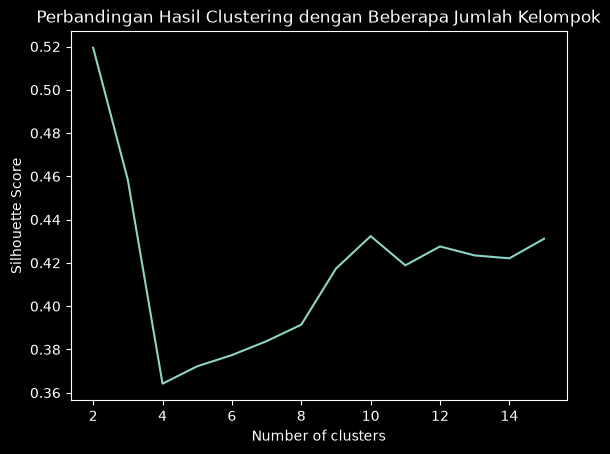

In [9]:
# Proses clustering dengan menggunakan K-Means yang mempertimbangkan beberapa
# nilai/jumlah kelompok
list_silhouetteScore = []
for i in range(2, 16):
  kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
  kmeans.fit(X)
  list_silhouetteScore.append(silhouette_score(X, kmeans.fit_predict(X)))
print ("Hasil Pencarian Nilai K Terbaik :\n")
plt.plot(range(2, 16), list_silhouetteScore)
plt.title('Perbandingan Hasil Clustering dengan Beberapa Jumlah Kelompok')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

## Analisis Silhouette Score

Dari perhitungan pada data ternormalisasi dengan `random_state=0`:

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|
| Silhouette | **0.5195** | 0.4584 | 0.3642 | 0.3722 | 0.3774 | 0.3838 | 0.3914 |  
  
<br>
  
| k | 9 | 10 | 11 | 12 | 13 | 14 | 15 |
|---|---|---|---|---|---|---|---|
| Silhouette | 0.4174 | 0.4324 | 0.4189 | 0.4276 | 0.4234 | 0.4221 | 0.4312 |

- **k = 2 menghasilkan skor tertinggi (0.5195)**, jelas di atas k=3 (0.4584) dan k=4 (0.3642).
- Setelah k=4 skor cenderung naik perlahan, tetapi tidak pernah melampaui k=2.
- Interpretasi: pemisahan paling jelas terjadi ketika data dibagi menjadi **dua kelompok besar**.


## Model K-Means Final (k=2)

Model dilatih ulang dengan `n_clusters=2` dan parameter yang sama, lalu `fit_predict(X)` mengembalikan label klaster setiap pelanggan (0 atau 1).


In [10]:
# Penggunaan model clustering dengan nilai cluster yang dianggap terbaik
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=0)
kmeans.fit(X)
print(kmeans.fit_predict(X))

[0 0 1 1 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 1 0 1 0 1 1 1
 0 0 1 0 1 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 0 0 1 1 0 0 0 0
 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 1
 1 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1
 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0]


c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## Analisis Hasil Clustering K-Means

- Distribusi anggota: **klaster 0 = 88 pelanggan**, **klaster 1 = 112 pelanggan**.
- Silhouette Score model final: **0.5195**; Davies-Bouldin Index: **0.8173**.
- Skor 0.5195 tergolong *moderate structure*: klaster cukup terpisah, tetapi masih ada titik di perbatasan.
- Label 0 dan 1 bersifat arbitrer (tidak menunjukkan tingkat "premium"); keduanya hanya penanda kelompok.


## Visualisasi 3D K-Means

Scatter 3D memakai `data_pca` (PC1-PC3) dengan warna berdasarkan label klaster K-Means. Visualisasi ini membantu melihat apakah klaster terpisah pada ruang varians terbesar.


c:\Anaconda\anaconda install\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


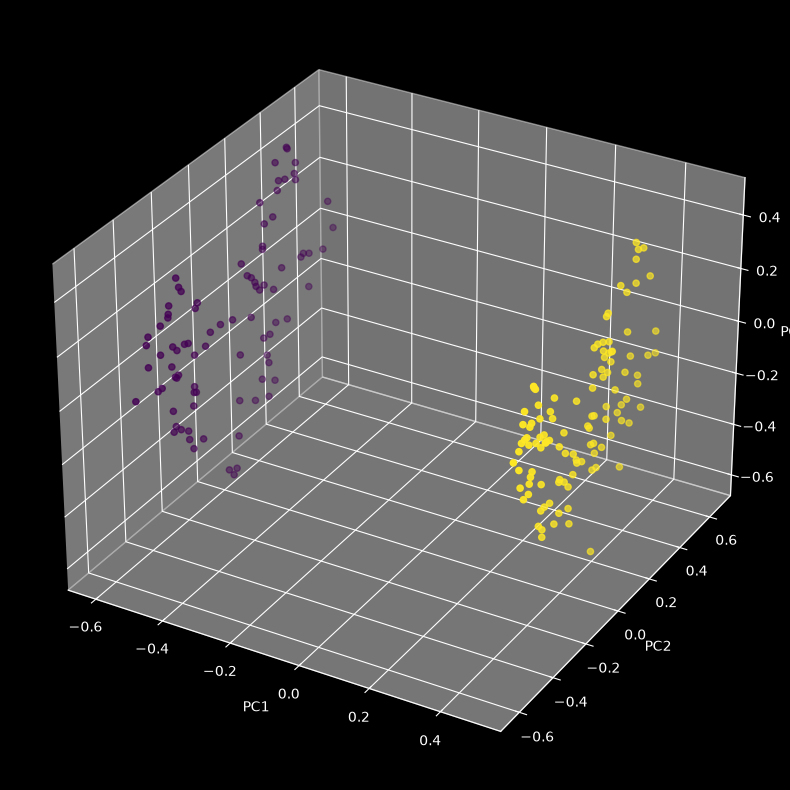

In [11]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi dan hasil clustering dengan K-Means
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'], c=kmeans.fit_predict(X))
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

## Analisis Visualisasi K-Means

- Dua klaster tampak terpisah pada ruang PC1-PC3, sejalan dengan Silhouette Score 0.5195.
- Pemisahan paling terlihat pada bidang PC1-PC2; PC3 menambah kedalaman tetapi tidak mengubah kesimpulan.
- Titik-titik di sekitar batas klaster menjelaskan mengapa skor tidak mendekati 1.


# Clustering dengan Agglomerative dan Davies-Bouldin Index

**Agglomerative Clustering** adalah hierarchical clustering *bottom-up*: setiap titik dimulai sebagai klaster sendiri, lalu klaster terdekat digabung berulang sampai tersisa $k$ klaster.

`linkage='complete'` berarti jarak antara dua klaster diukur dari **pasangan titik terjauh**:

$$
d(C_a, C_b) = \max_{x \in C_a,\; y \in C_b} \|x - y\|
$$

Linkage ini cenderung menghasilkan klaster yang kompak.

**Davies-Bouldin Index (DBI)** mengukur rasio *within-cluster scatter* terhadap *between-cluster separation*:

$$
DBI = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \frac{s_i + s_j}{d(c_i, c_j)}
$$

- $s_i$ = rata-rata jarak anggota klaster $i$ ke centroid-nya (compactness),
- $d(c_i, c_j)$ = jarak antar centroid (separation).

**Makin kecil DBI makin baik**, karena klaster rapat dan saling berjauhan.


## Pencarian Nilai K Terbaik (DBI)

Loop `k = 2..15`:

1. latih `AgglomerativeClustering(n_clusters=k, linkage='complete')`,
2. hitung `davies_bouldin_score(X, label)`,
3. simpan hasilnya ke `list_daviesBouldinScore`.

Plot menampilkan DBI terhadap jumlah klaster. Nilai $k$ dengan DBI **terendah** dianggap yang terbaik.


Hasil Pencarian Nilai Cluster Terbaik :



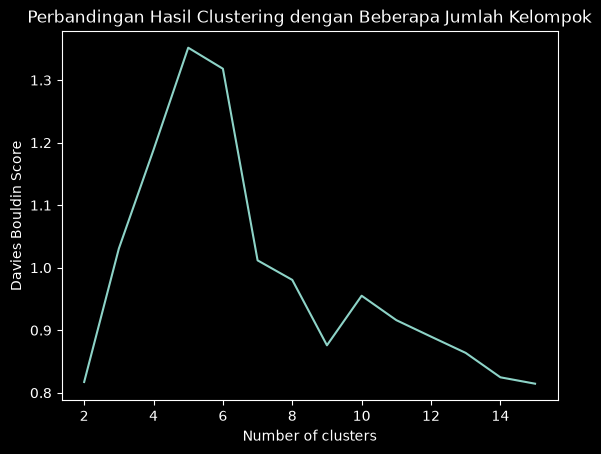

In [12]:
# Proses clustering dengan menggunakan Agglomerative yang mempertimbangkan beberapa
# nilai/jumlah kelompok
list_daviesBouldinScore = []
for i in range(2, 16):
  aggloClustering = AgglomerativeClustering(n_clusters=i, linkage='complete')
  aggloClustering.fit(X)
  list_daviesBouldinScore.append(davies_bouldin_score(X, aggloClustering.fit_predict(X)))
print ("Hasil Pencarian Nilai Cluster Terbaik :\n")
plt.plot(range(2, 16), list_daviesBouldinScore)
plt.title('Perbandingan Hasil Clustering dengan Beberapa Jumlah Kelompok')
plt.xlabel('Number of clusters')
plt.ylabel('Davies Bouldin Score')
plt.show()

## Analisis Davies-Bouldin Index

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|
| DBI | **0.8173** | 1.0306 | 1.1885 | 1.3519 | 1.3182 | 1.0118 | 0.9805 |

<br>

| k | 9 | 10 | 11 | 12 | 13 | 14 | 15 |
|---|---|---|---|---|---|---|---|
| DBI | 0.8759 | 0.9552 | 0.9161 | 0.8898 | 0.8638 | 0.8247 | **0.8145** |

- DBI **minimum absolut** ada di **k=15 (0.8145)**, bukan k=2 (0.8173).
- Namun selisih k=2 terhadap k=15 hanya **0.0028** (sekitar 0.34%), sangat tipis dan praktis dapat diabaikan.
- DBI cenderung membaik seiring bertambahnya klaster karena jarak antar centroid mengecil dan anggota tiap klaster makin rapat. Karena itu, DBI saja tidak cukup untuk memilih $k$; perlu dibandingkan dengan metrik lain seperti Silhouette.
- Secara metodologis, klaim "k=2 adalah DBI terbaik" perlu diluruskan: k=2 adalah **praktis terbaik** dan konsisten dengan hasil K-Means, tetapi bukan minimum absolut.


## Model Agglomerative Final (k=2)

Model dilatih dengan `n_clusters=2` dan `linkage='complete'`, lalu label klaster diambil dari `fit_predict(X)`.


In [13]:
# Penggunaan model clustering dengan nilai cluster yang dianggap terbaik
aggloClustering = AgglomerativeClustering(n_clusters=2, linkage='complete')
aggloClustering.fit(X)
print(aggloClustering.fit_predict(X))

[0 0 1 1 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 1 0 1 0 1 1 1
 0 0 1 0 1 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 0 0 1 1 0 0 0 0
 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 1
 1 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1
 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0]


## Analisis Hasil Agglomerative

- Distribusi anggota: **klaster 0 = 88 pelanggan**, **klaster 1 = 112 pelanggan**, identik dengan K-Means.
- Label Agglomerative **sama persis dengan K-Means untuk seluruh 200 data** (200/200).
- Silhouette Score 0.5195 dan DBI 0.8173, sama dengan K-Means.
- Artinya, pada dataset ini dan k=2, kedua algoritma menemukan partisi yang sama. Struktur data cukup tegas sehingga metode yang berbeda konvergen ke pembagian yang sama.


## Visualisasi 3D Agglomerative

Scatter 3D `data_pca` dengan warna berdasarkan label klaster Agglomerative.


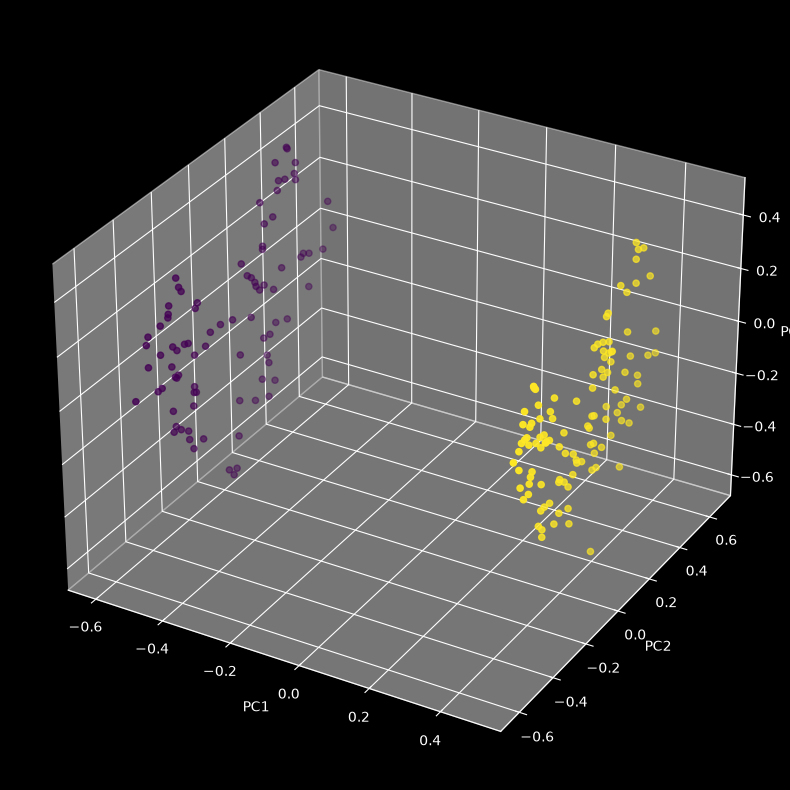

In [14]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi dan hasil clustering dengan Agglomerative
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'], c=aggloClustering.fit_predict(X))
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

## Analisis Visualisasi Agglomerative

- Pola visual identik dengan K-Means karena label klasternya sama.
- Temuan ini memperkuat bahwa partisi 2 klaster stabil terhadap pilihan algoritma.


# Analisis Perbandingan & Kesimpulan

## Tabel Perbandingan Hasil (k=2)

| Aspek | K-Means | Agglomerative (complete) |
|---|---|---|
| Metrik evaluasi | Silhouette Score | Davies-Bouldin Index |
| Nilai metrik | **0.5195** (makin tinggi makin baik) | **0.8173** (makin rendah makin baik) |
| Distribusi klaster | 88 vs 112 | 88 vs 112 |
| Kesamaan label | - | Identik 200/200 dengan K-Means |
| Parameter kunci | `init='k-means++'`, `n_init=10` | `linkage='complete'` |

## Temuan

1. **k=2 adalah pilihan terbaik untuk K-Means** berdasarkan Silhouette Score (0.5195), jelas mengungguli k=3 (0.4584) dan k=4 (0.3642).
2. **Kedua algoritma menghasilkan partisi identik** pada k=2. Perbedaan algoritma tidak berpengaruh ketika struktur data sudah tegas.
3. **DBI minimum sebenarnya ada di k=15 (0.8145)**, bukan k=2 (0.8173). Selisihnya hanya 0.0028 sehingga pemilihan k=2 tetap dapat diterima, terutama untuk konsistensi perbandingan dan interpretasi. Namun klaim bahwa k=2 adalah DBI terbaik perlu diluruskan menjadi *praktis terbaik*.
4. **Kualitas klaster moderat** (Silhouette sekitar 0.52): pemisahan terlihat, tetapi masih ada titik di batas klaster.

## Keterbatasan

- `Gender` hanya biner dan setelah normalisasi skalanya kecil, sehingga kontribusinya terhadap jarak relatif terbatas.
- PCA dipakai hanya untuk visualisasi; clustering memakai 4 fitur asli yang ternormalisasi.
- Pemilihan k pada Agglomerative mengandalkan DBI yang cenderung membaik seiring bertambahnya klaster, sehingga perlu dibandingkan dengan metrik lain.
- Dataset hanya 200 baris, sehingga hasil belum tentu tergeneralisasi ke populasi yang lebih besar.

## Kesimpulan

Kedua metode berhasil membagi 200 pelanggan menjadi **dua segmen (88 dan 112)** dengan kualitas cukup baik. K-Means unggul dari sisi kecepatan dan pemilihan k yang didukung Silhouette Score, sedangkan Agglomerative menawarkan struktur hierarkis. Pada kasus ini keduanya konvergen ke solusi yang sama.
